## Import Statements

In [27]:
import os
from pathlib import Path 

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, f1_score, confusion_matrix, precision_score
from xgboost import XGBClassifier
import joblib

## placeholder data set
from sklearn.datasets import load_breast_cancer

## Export Paths

In [21]:
# Get the project root directory (one level up from the 'notebooks' folder)
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# Define absolute paths for output directories
REPORTS_DIR = ROOT_DIR / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
TABLES_DIR = REPORTS_DIR / 'tables'
MODELS_DIR = ROOT_DIR / 'models'

# Ensure directories exist at the root level
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

## Load Data

In [4]:
data = load_breast_cancer() # PLACEHOLDER DATA

## Data Exploration

In [5]:
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

print(X.head())
print(y.value_counts())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

## Data Cleanup

VERY IMPORTANT: Make sure you do REMOVE any "leaky features". That is, variables that would leak the outcome you're trying to predict. This can include:
- DMFT
- Number of new cavities this year → directly tells the model the outcome

## Train Test Split

We will do a 70-30 split.

**IMPORTANT: DO NOT RUN TRAIN-TEST-SPLIT MORE THAN ONCE** to avoid data leakage!!

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.3, 
                                                    random_state=42)

## Setup Pipelines

Instantiate the pipelines for the three models. For caries risk prediction, we will be using **classification models* as we will be predicting categorical labels (low/high caries risk)

### Logistic Regression
We use a logistic regression model as a baseline for our other models: Random Forest and XGBoost. Logistic regression models are used to predict binary probabilities (low/high caries risk) by modeling the log-odds of the outcome as a linear combination of input features.

### Random Forest
Random Forest is an ensemble learning method that constructs a collection of independent decision trees during training. By combining the predictions of multiple trees (via majority voting), it reduces model variance, prevents overfitting, and effectively handles non-linear relationships and interactions among clinical risk factors.

### XGBoost
eXtreme Gradient Boosting (XGBoost) is an optimized gradient-boosted decision tree algorithm that builds trees sequentially, where each new tree corrects the residual errors of the previous ones. It is highly efficient for tabular clinical data, offering built-in regularization to prevent overfitting and strong predictive accuracy for complex, high-dimensional datasets.

In [7]:
pipelines = {
    'log_reg': Pipeline([
        ('scaler', StandardScaler()), 
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'rf': Pipeline([
        ('model', RandomForestClassifier(random_state=42))
    ]),
    'xgb': Pipeline([
        ('model', XGBClassifier(eval_metric='logloss', random_state=42))
    ])
}

In [8]:
param_grids = {
    'log_reg': {
        'model__C': [0.01, 0.1, 1, 10]
    },
    'rf': {
        'model__n_estimators': [100, 300, 500],
        'model__max_depth': [None, 5, 10, 20],
        'model__min_samples_leaf': [1, 5, 10]
    },
    'xgb': {
        'model__n_estimators': [100, 300, 500],
        'model__max_depth': [3, 5, 7],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__min_child_weight': [1, 5, 10]
    }
}

CV_FOLDS = 5 # 5 is already the default; specified here to be explicit
SCORING = 'roc_auc'


grids = {
    'log_reg': GridSearchCV(pipelines['log_reg'], param_grids['log_reg'],cv=CV_FOLDS, scoring=SCORING),
    'rf': GridSearchCV(pipelines['rf'], param_grids['rf'], cv=CV_FOLDS, scoring=SCORING),
    'xgb': GridSearchCV(pipelines['xgb'], param_grids['xgb'], cv=CV_FOLDS, scoring=SCORING)
}

## Training

In [9]:
for name, grid in grids.items():
    grid.fit(X_train, y_train)
    print(f"{name} trained successfully.")

log_reg trained successfully.
rf trained successfully.
xgb trained successfully.


## EVALUATION
Evaluation performance of each model according to the following metrics:
- Accuracy
- Sensitivity
- Specificity
- Precision
- AUC-ROC

In [28]:
os.makedirs('reports/figures', exist_ok=True)
os.makedirs('reports/tables', exist_ok=True)

best_model_name = None
best_accuracy = 0.0
performance_results = {}

for name, grid in grids.items():
    y_pred = grid.predict(X_test)
    y_proba = grid.predict_proba(X_test)[:, 1]

    # Accuracy
    acc = accuracy_score(y_test, y_pred)

    if acc > best_accuracy:
        best_accuracy = acc
        best_model_name = name
        best_model_pipeline = grid


    # TODO: save each result to performance_results dict
    # Sensitivity
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    sensitivity = tp / (tp + fn)

    # Specificity
    specificity = tn / (tn + fp)

    # Precision
    precision = precision_score(y_test, y_pred, zero_division=0)

    # Feature Importance
    best_est = grid.best_estimator_
    if hasattr(best_est, 'feature_importances_'):
        importances = best_est.feature_importances_
    elif hasattr(best_est, 'named_steps') and hasattr(best_est.named_steps['model'], 'coef_'):
        importances = best_est.named_steps['model'].coef_[0]
    else:
        importances = None

    # AUC-ROC
    roc_auc = roc_auc_score(y_test, y_proba)

    # F1
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Best params for each model:
    print(f"Best params for {name}: {grid.best_params_}")
    print(f"Best CV score for {name}: {grid.best_score_}")

    # Performance Results
    performance_results[name] = {
        'accuracy': acc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': precision,
        'f1_score': f1,
        'AUC-ROC': roc_auc,
        'y_proba': y_proba,
        'importances': importances
    }


    print(f"--- {name.upper()} ---")
    print(f"Best Params: {grid.best_params_}")
    print(f"Best CV Score (ROC-AUC): {grid.best_score_:.4f}")
    print(f"Test Accuracy: {acc:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f} | ROC-AUC: {roc_auc:.4f}\n")

Best params for log_reg: {'model__C': 1}
Best CV score for log_reg: 0.9928839784189538
--- LOG_REG ---
Best Params: {'model__C': 1}
Best CV Score (ROC-AUC): 0.9929
Test Accuracy: 0.9825 | Sensitivity: 0.9815 | Specificity: 0.9841 | ROC-AUC: 0.9979

Best params for rf: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best CV score for rf: 0.9892886699507389
--- RF ---
Best Params: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 300}
Best CV Score (ROC-AUC): 0.9893
Test Accuracy: 0.9708 | Sensitivity: 0.9907 | Specificity: 0.9365 | ROC-AUC: 0.9971

Best params for xgb: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__min_child_weight': 1, 'model__n_estimators': 500}
Best CV score for xgb: 0.9904277738681679
--- XGB ---
Best Params: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__min_child_weight': 1, 'model__n_estimators': 500}
Best CV Score (ROC-AUC): 0.9904
Test Accuracy: 0.9766 | Sensitivity: 

## Compare Models

Now we compare the three models (Logistic Regression, Random Forest, XGBoost) based on their scores

In [29]:
# Create summary DataFrame from performance_results
summary_df = pd.DataFrame(performance_results).T[
    ['accuracy', 'sensitivity', 'specificity', 'precision', 'f1_score', 'AUC-ROC']
]
summary_df.columns = ['Accuracy', 'Sensitivity (Recall)', 'Specificity', 'Precision', 'F1-Score', 'ROC-AUC']

# Identify the top model for each metric dynamically
print("=== BEST PERFORMING MODEL PER METRIC ===")
for metric in summary_df.columns:
    top_model = summary_df[metric].idxmax()
    top_score = summary_df.loc[top_model, metric]
    print(f"Best {metric:12s}: {top_model.upper()} ({top_score:.4f})")

# Save CSV table to reports/tables/
summary_df.to_csv(TABLES_DIR / 'model_performance_summary.csv')
print("Saved summary table to reports/tables/model_performance_summary.csv")

summary_df

=== BEST PERFORMING MODEL PER METRIC ===
Best Accuracy    : LOG_REG (0.9825)
Best Sensitivity (Recall): RF (0.9907)
Best Specificity : LOG_REG (0.9841)
Best Precision   : LOG_REG (0.9907)
Best F1-Score    : LOG_REG (0.9860)
Best ROC-AUC     : LOG_REG (0.9979)
Saved summary table to reports/tables/model_performance_summary.csv


,Accuracy,Sensitivity (Recall),Specificity,Precision,F1-Score,ROC-AUC
log_reg,0.982456,0.981481,0.984127,0.990654,0.986047,0.997942
rf,0.97076,0.990741,0.936508,0.963964,0.977169,0.997061
xgb,0.976608,0.981481,0.968254,0.981481,0.981481,0.994562


## Select Best Overall Model
To select the best overall model, we will use **ROC-AUC as the primary metric** and **sensitivity as the secondary metric**.


In [30]:
# Sort by primary metric (ROC-AUC), then secondary metric (Sensitivity) descending
sorted_summary = summary_df.sort_values(
    by=['ROC-AUC', 'Sensitivity (Recall)'], 
    ascending=[False, False]
)

best_overall_name = sorted_summary.index[0]
best_auc = sorted_summary.loc[best_overall_name, 'ROC-AUC']
best_sens = sorted_summary.loc[best_overall_name, 'Sensitivity (Recall)']

print(f"🏆 OVERALL BEST MODEL: {best_overall_name.upper()}")
print(f"Primary Metric (ROC-AUC): {best_auc:.4f}")
print(f"Tie-Breaker (Sensitivity): {best_sens:.4f}")

🏆 OVERALL BEST MODEL: LOG_REG
Primary Metric (ROC-AUC): 0.9979
Tie-Breaker (Sensitivity): 0.9815


### Figures

ROC curve fo each model in separate graphs:

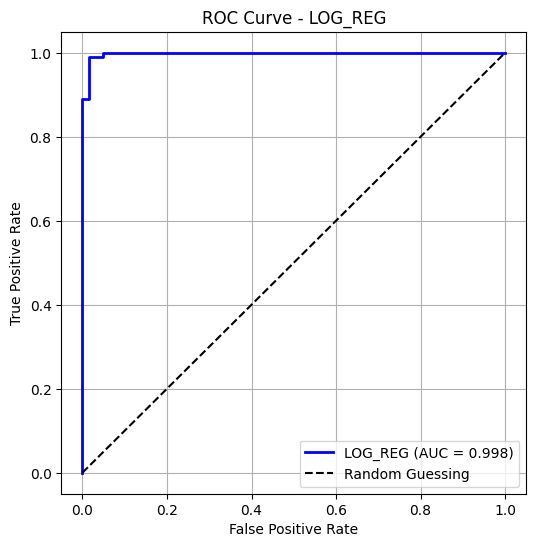

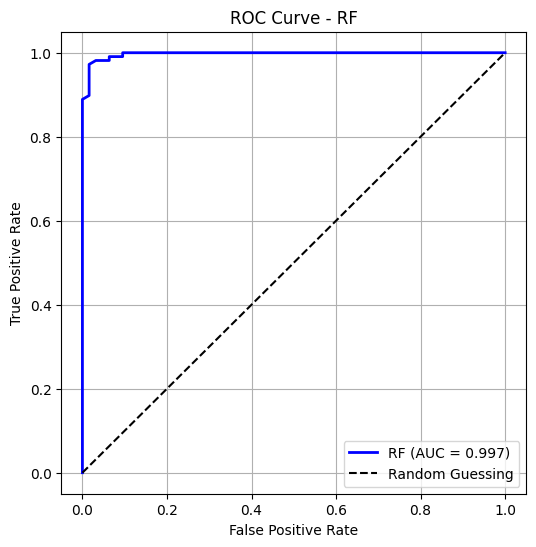

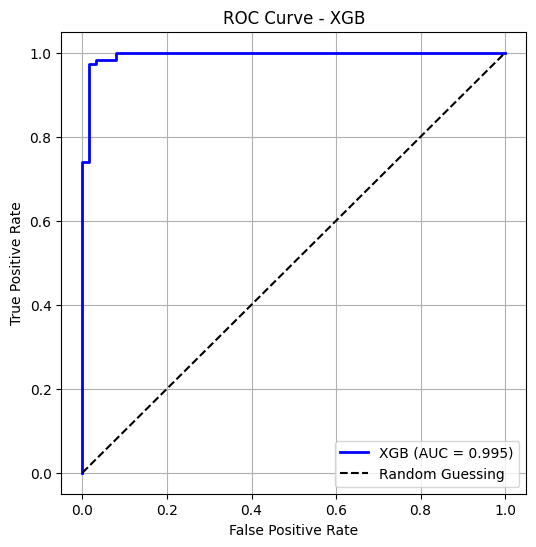

In [31]:
for name, data in performance_results.items():
    fpr, tpr, _ = roc_curve(y_test, data['y_proba'])
    
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f"{name.upper()} (AUC = {data['AUC-ROC']:.3f})", color='blue', linewidth=2)
    plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {name.upper()}')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

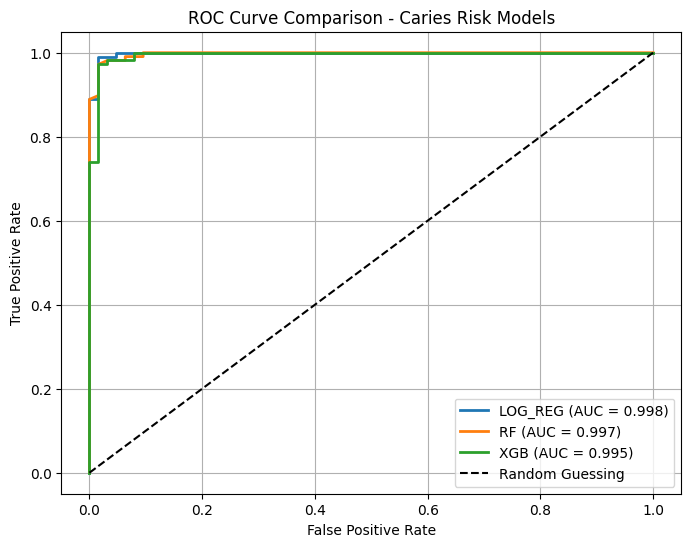

In [32]:
# Combined ROC Plot and Export
plt.figure(figsize=(8, 6))

for name, data in performance_results.items():
    fpr, tpr, _ = roc_curve(y_test, data['y_proba'])
    plt.plot(fpr, tpr, linewidth=2, label=f"{name.upper()} (AUC = {data['AUC-ROC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Caries Risk Models')
plt.legend(loc='lower right')
plt.grid(True)

# Save figure before show()
plt.savefig(FIGURES_DIR / 'roc_curve_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

ROC curve of each model in one graph:

## Export Best Model

Export the best performing caries risk prediction model for production

In [33]:
joblib.dump(grids[best_model_name].best_estimator_, MODELS_DIR / 'caries-risk-predictor.pkl')

['f:\\Research\\Caries Risk Prediction ML\\caries-risk-prediction-ml\\models\\caries-risk-predictor.pkl']